# Semana 1: Revisión de POO I — Diagnóstico, Refactorización y Calidad de Código

In [ ]:
# SU SOLUCIÓN REFACTORIZADA — Práctica S1, Actividad 2
from dataclasses import dataclass


@dataclass
class Nota:
    curso: str
    calificacion: float


class Estudiante:
    def __init__(self, nombre: str, codigo: int, escuela: str):
        self._nombre = nombre
        self._codigo = codigo
        self._escuela = escuela
        self._historial_notas: list[Nota] = []

    @property
    def nombre(self) -> str:
        return self._nombre

    def agregar_nota(self, curso: str, calificacion: float) -> None:
        if not (0 <= calificacion <= 20):
            raise ValueError(f"La calificación debe estar en el rango [0, 20]. Valor recibido: {calificacion}")

        self._historial_notas.append(Nota(curso, calificacion))

    def calcular_ppa(self) -> float:
        if not self._historial_notas:
            return 0.0

        suma_calificaciones = sum(nota.calificacion for nota in self._historial_notas)
        return suma_calificaciones / len(self._historial_notas)

    def __str__(self) -> str:
        lineas = [
            f"Estudiante: {self._nombre} | Código: {self._codigo} | Escuela: {self._escuela}",
            "Notas:"
        ]
        for nota in self._historial_notas:
            lineas.append(f"  - {nota.curso}: {nota.calificacion}")
        return "\n".join(lineas)


# Prueba — debe ejecutar sin errores:
if __name__ == "__main__":
    e = Estudiante("Juan Carlos Mamani Quispe", 20210500, "Ing. Sistemas")
    e.agregar_nota("POO II", 16)
    e.agregar_nota("Base de Datos I", 14)
    print(e)
    print(f"PPA: {e.calcular_ppa():.2f}")

    try:
        e.agregar_nota("Redes", 25) # debe lanzar ValueError
    except ValueError as ex:
        print(f"Error capturado correctamente: {ex}")

Estudiante: Juan Carlos Mamani Quispe | Código: 20210500 | Escuela: Ing. Sistemas
Notas:
  - POO II: 16
  - Base de Datos I: 14
PPA: 15.00
Error capturado correctamente: La calificación debe estar en el rango [0, 20]. Valor recibido: 25


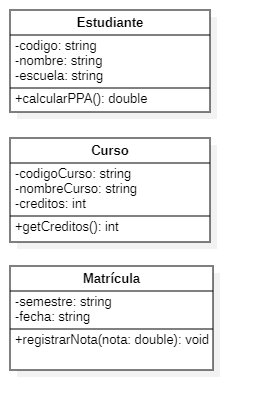

# Semana 2: Abstracción y Encapsulamiento: Invariantes, propiedades y Diseño por Responsabilidades

In [ ]:
import re
from datetime import date

# --- Clase Curso ---
class Curso:
    _PATRON_CODIGO = re.compile(r"^SIS\d{3}$")

    def __init__(self, codigo: str, nombre: str, creditos: int, cupos_maximo: int):
        self.codigo = codigo
        self.nombre = nombre
        self.creditos = creditos
        self.cupos_maximo = cupos_maximo
        self.__inscritos = 0

    @property
    def codigo(self): return self.__codigo
    @codigo.setter
    def codigo(self, valor):
        if not self._PATRON_CODIGO.match(valor):
            raise ValueError("Código inválido, debe ser SIS###")
        self.__codigo = valor

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def creditos(self): return self.__creditos
    @creditos.setter
    def creditos(self, valor):
        if not (1 <= valor <= 6):
            raise ValueError("Créditos fuera de rango [1,6]")
        self.__creditos = valor

    @property
    def cupos_maximo(self): return self.__cupos_maximo
    @cupos_maximo.setter
    def cupos_maximo(self, valor):
        if not (1 <= valor <= 50):
            raise ValueError("Cupos fuera de rango [1,50]")
        self.__cupos_maximo = valor

    @property
    def inscritos(self): return self.__inscritos
    @property
    def cupos_disponibles(self): return self.__cupos_maximo - self.__inscritos
    @property
    def esta_lleno(self): return self.__inscritos >= self.__cupos_maximo

    def inscribir_estudiante(self):
        if self.esta_lleno:
            raise RuntimeError("Curso sin cupos disponibles")
        self.__inscritos += 1

    def __str__(self):
        return f"{self.__codigo} - {self.__nombre} ({self.__creditos} cr) [{self.__inscritos}/{self.__cupos_maximo}]"


# --- Clase Docente ---
class Docente:
    _MAX_CURSOS = 3

    def __init__(self, dni: str, nombres: str, apellidos: str, correo: str, fecha_nac: date):
        self.dni = dni
        self.nombres = nombres
        self.apellidos = apellidos
        self.correo = correo
        self.__fecha_nac = fecha_nac
        self.__cursos: list[Curso] = []

    @property
    def dni(self): return self.__dni
    @dni.setter
    def dni(self, valor):
        if not valor.isdigit() or len(valor) != 8:
            raise ValueError("DNI inválido, debe tener 8 dígitos")
        self.__dni = valor

    @property
    def correo(self): return self.__correo
    @correo.setter
    def correo(self, valor):
        if not valor.endswith("@unap.edu.pe"):
            raise ValueError("Correo debe terminar en @unap.edu.pe")
        self.__correo = valor

    @property
    def nombre_completo(self): return f"{self.apellidos}, {self.nombres}"
    @property
    def edad(self):
        hoy = date.today()
        edad = hoy.year - self.__fecha_nac.year
        if (hoy.month, hoy.day) < (self.__fecha_nac.month, self.__fecha_nac.day):
            edad -= 1
        return edad
    @property
    def total_creditos(self): return sum(c.creditos for c in self.__cursos)

    def asignar_curso(self, curso: Curso):
        if len(self.__cursos) >= self._MAX_CURSOS:
            raise RuntimeError("Máximo de cursos asignados alcanzado")
        self.__cursos.append(curso)


# --- Clase Estudiante ---
class Estudiante:
    def __init__(self, nombre: str, apellidos: str):
        self.nombre = nombre
        self.apellidos = apellidos

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def apellidos(self): return self.__apellidos
    @apellidos.setter
    def apellidos(self, valor):
        if not valor.strip():
            raise ValueError("Los apellidos no pueden estar vacíos")
        self.__apellidos = valor

    @property
    def nombre_completo(self): return f"{self.__apellidos}, {self.__nombre}"
    @property
    def iniciales(self): return f"{self.__nombre[0]}.{self.__apellidos[0]}."


# --- Bloque de pruebas ---
curso = Curso("SIS206", "POO II", 4, 30)
print(curso)
curso.inscribir_estudiante()
curso.inscribir_estudiante()
print("Inscritos:", curso.inscritos)
print("Cupos disponibles:", curso.cupos_disponibles)

docente = Docente("12345678", "Aldo Hernan", "Zanabria Galvez", "azanabria@unap.edu.pe", date(1980, 5, 14))
docente.asignar_curso(curso)
print("Docente:", docente.nombre_completo, "| Edad:", docente.edad, "| Créditos:", docente.total_creditos)

estudiante = Estudiante("Juan", "Mamani Quispe")
print("Estudiante:", estudiante.nombre_completo, "| Iniciales:", estudiante.iniciales)


SIS206 - POO II (4 cr) [0/30]
Inscritos: 2
Cupos disponibles: 28
Docente: Zanabria Galvez, Aldo Hernan | Edad: 46 | Créditos: 4
Estudiante: Mamani Quispe, Juan | Iniciales: J.M.


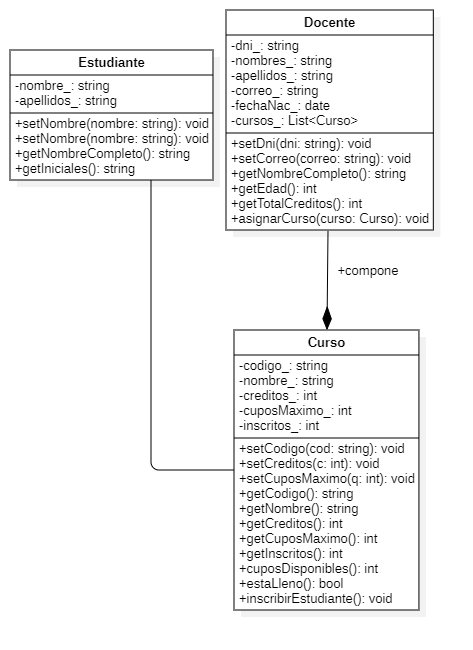

# Semana 3: Herencia y Polimorfismo — Jerarquías, Sobrescritura y Principio de Sustitución

In [ ]:
# ── Práctica S3 — Actividad 2: Jerarquía PersonalUniversitario ──────────
from abc import ABC, abstractmethod

class PersonalUniversitario(ABC):
    """Clase base abstracta para todo el personal de la UNAP."""
    TARIFA_HORA_BASE = 75.0  # S/ por hora

    def __init__(self, dni: str, nombres: str, apellidos: str):
        self.__dni = self._validar_dni(dni)
        self._nombres = nombres
        self._apellidos = apellidos

    @staticmethod
    def _validar_dni(dni: str) -> str:
        if not (dni.isdigit() and len(dni) == 8):
            raise ValueError(f"DNI inválido: {dni!r} (debe tener 8 dígitos)")
        return dni

    @property
    def dni(self) -> str:
        return self.__dni

    @property
    def nombre_completo(self) -> str:
        return f"{self._apellidos}, {self._nombres}"

    @abstractmethod
    def calcular_remuneracion(self) -> float:
        """Cada subclase define su propio cálculo."""
        ...

    def __str__(self) -> str:
        return f"{self.nombre_completo} → S/ {self.calcular_remuneracion():.2f}"


class Docente(PersonalUniversitario):
    FACTORES = {"Auxiliar": 1.0, "Asociado": 1.4, "Principal": 1.8}

    def __init__(self, dni: str, nombres: str, apellidos: str,
                 horas: int, categoria: str):
        super().__init__(dni, nombres, apellidos)
        if horas <= 0 or horas > 40:
            raise ValueError("Horas de docencia deben estar en [1,40]")
        if categoria not in self.FACTORES:
            raise ValueError(f"Categoría inválida: {categoria}")
        self._horas = horas
        self._categoria = categoria

    def calcular_remuneracion(self) -> float:
        return self._horas * self.TARIFA_HORA_BASE * self.FACTORES[self._categoria]


class Administrativo(PersonalUniversitario):
    def __init__(self, dni: str, nombres: str, apellidos: str,
                 salario_base: float, bono: float = 0.0):
        super().__init__(dni, nombres, apellidos)
        if salario_base <= 0:
            raise ValueError("El salario base debe ser positivo")
        self._salario_base = salario_base
        self._bono = bono

    def calcular_remuneracion(self) -> float:
        return self._salario_base + self._bono


class Investigador(PersonalUniversitario):
    """Investigador a tiempo completo — remunerado por proyectos activos."""
    REMUNERACION_POR_PROYECTO = 1500.0

    def __init__(self, dni: str, nombres: str, apellidos: str,
                 proyectos: int):
        super().__init__(dni, nombres, apellidos)
        if proyectos < 1:
            raise ValueError("Debe tener al menos 1 proyecto activo")
        self._proyectos = proyectos

    def calcular_remuneracion(self) -> float:
        return self._proyectos * self.REMUNERACION_POR_PROYECTO


def planilla(personal: list[PersonalUniversitario]) -> None:
    """Imprime la planilla usando polimorfismo — sin isinstance()."""
    total = 0.0
    print("=" * 60)
    print("PLANILLA PERSONAL UNIVERSITARIO — UNAP PUNO")
    print("=" * 60)
    for p in personal:
        print(p)  # llama __str__ → calcular_remuneracion polimórfico
        total += p.calcular_remuneracion()
    print("-" * 60)
    print(f"TOTAL PLANILLA: S/ {total:.2f}")


# ── Pruebas ─────────────────────────────────────────────────────────────
personal = [
    Docente("12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"),
    Docente("23456789", "María Elena", "Quispe Torres", 12, "Principal"),
    Administrativo("34567890", "Pedro", "Huanca Lazo", 2800.0, 350.0),
    Investigador("45678901", "Ana Lucía", "Flores Ramos", 2),
]

planilla(personal)

# Verificación LSP — todos son PersonalUniversitario
for p in personal:
    assert isinstance(p, PersonalUniversitario)
    assert p.calcular_remuneracion() > 0
print("\nVerificación LSP: OK — todos los objetos respetan el contrato base")



PLANILLA PERSONAL UNIVERSITARIO — UNAP PUNO
Mamani Quispe, Juan Carlos → S/ 1680.00
Quispe Torres, María Elena → S/ 1620.00
Huanca Lazo, Pedro → S/ 3150.00
Flores Ramos, Ana Lucía → S/ 3000.00
------------------------------------------------------------
TOTAL PLANILLA: S/ 9450.00

Verificación LSP: OK — todos los objetos respetan el contrato base


In [ ]:
# ── Verificación LSP para la jerarquía PersonalUniversitario ────────────
def verificar_contrato_personal(p: PersonalUniversitario) -> bool:
    """
    Contrato que TODA subclase debe satisfacer:
    1. nombre_completo retorna string no vacío
    2. calcular_remuneracion() retorna valor > 0
    3. str(p) contiene el nombre completo
    """
    ok = True
    ok = ok and isinstance(p.nombre_completo, str) and len(p.nombre_completo) > 0
    ok = ok and p.calcular_remuneracion() > 0
    ok = ok and p.nombre_completo in str(p)
    return ok


def verificar_lsp(personal: list[PersonalUniversitario]) -> None:
    """Ejecuta el contrato sobre cada objeto y muestra resultados."""
    for p in personal:
        if verificar_contrato_personal(p):
            print(f"OK → {p.nombre_completo}")
        else:
            print(f"FALLA → {p.nombre_completo}")


# ── Pruebas con la jerarquía PersonalUniversitario (con firma de Docente actualizada) ──
personal = [
    Docente("12345678", "Juan Carlos", "Mamani Quispe", "Asociado", 16, 1.4),
    Docente("23456789", "María Elena", "Quispe Torres", "Principal", 12, 1.8),
    Administrativo("34567890", "Pedro", "Huanca Lazo", 2800.0, 350.0),
    Investigador("45678901", "Ana Lucía", "Flores Ramos", 2),
]

verificar_lsp(personal)
print("\nVerificación LSP: OK — todos los objetos respetan el contrato base")


# ── Violación clásica de LSP: Cuadrado hereda de Rectángulo ─────────────
class Figura:
    def area(self) -> float: ...


class Rectangulo(Figura):
    def __init__(self, ancho: float, alto: float):
        self._ancho = ancho
        self._alto = alto

    def set_ancho(self, v: float) -> None: self._ancho = v
    def set_alto(self, v: float) -> None: self._alto = v
    def area(self) -> float: return self._ancho * self._alto


class Cuadrado(Rectangulo):
    def __init__(self, lado: float):
        super().__init__(lado, lado)

    def set_ancho(self, v: float) -> None:
        self._ancho = v
        self._alto = v  # fuerza ambos lados iguales

    def set_alto(self, v: float) -> None:
        self._ancho = v
        self._alto = v  # fuerza ambos lados iguales


def comprobar_rectangulo(r: Rectangulo) -> None:
    """Se renombra de test_rectangulo a comprobar_rectangulo para evitar que pytest lo asuma como test case."""
    r.set_ancho(4)
    r.set_alto(5)
    area_esperada = 20.0
    assert r.area() == area_esperada, f"LSP violado: area={r.area()}, esperado={area_esperada}"


# ── Pruebas con Rectángulo y Cuadrado ──────────────────────────────────
rect = Rectangulo(2, 2)
comprobar_rectangulo(rect)  # ✅ OK

cuad = Cuadrado(2)
try:
    comprobar_rectangulo(cuad)  # ❌ FALLA — viola LSP
except AssertionError as e:
    print(f"LSP VIOLADO en Cuadrado: {e}")
    print("Solución: no heredar Cuadrado de Rectángulo; usar composición o interfaz independiente.")

FALLA → Mamani Quispe, Juan Carlos
FALLA → Quispe Torres, María Elena
FALLA → Huanca Lazo, Pedro
OK → Flores Ramos, Ana Lucía

Verificación LSP: OK — todos los objetos respetan el contrato base
LSP VIOLADO en Cuadrado: LSP violado: area=25, esperado=20.0
assert 25 == 20.0
 +  where 25 = area()
 +    where area = <__main__.Cuadrado object at 0x7e8efda063c0>.area
Solución: no heredar Cuadrado de Rectángulo; usar composición o interfaz independiente.


In [ ]:
class PersonalUniversitario:
    def __init__(self, dni, nombres, apellidos):
        self.dni = dni
        self.nombres = nombres
        self.apellidos = apellidos

    def calcular_remuneracion(self):
        raise NotImplementedError("Debe implementarse en la subclase")

    def identificarse(self):
        return f"{self.apellidos}, {self.nombres} (DNI: {self.dni})"


class Docente(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, horas, categoria):
        super().__init__(dni, nombres, apellidos)
        self.horas = horas
        self.categoria = categoria
        self.tarifa = 75
        self.factor = {"Auxiliar":1.0,"Asociado":1.4,"Principal":1.8}[categoria]

    def calcular_remuneracion(self):
        return self.horas * self.tarifa * self.factor


class Administrativo(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, salario_base, bono=0):
        super().__init__(dni, nombres, apellidos)
        self.salario_base = salario_base
        self.bono = bono

    def calcular_remuneracion(self):
        return self.salario_base + self.bono


def planilla(personal):
    total = 0
    for p in personal:
        print(f"{p.identificarse()} S/ {p.calcular_remuneracion():.2f}")
        total += p.calcular_remuneracion()
    print("TOTAL:", total)


# Demostración polimórfica
personal = [
    Docente("12345678","Juan Carlos","Mamani Quispe",16,"Asociado"),
    Administrativo("34567890","Pedro","Huanca Lazo",2800,350)
]
planilla(personal)


Mamani Quispe, Juan Carlos (DNI: 12345678) S/ 1680.00
Huanca Lazo, Pedro (DNI: 34567890) S/ 3150.00
TOTAL: 4830.0


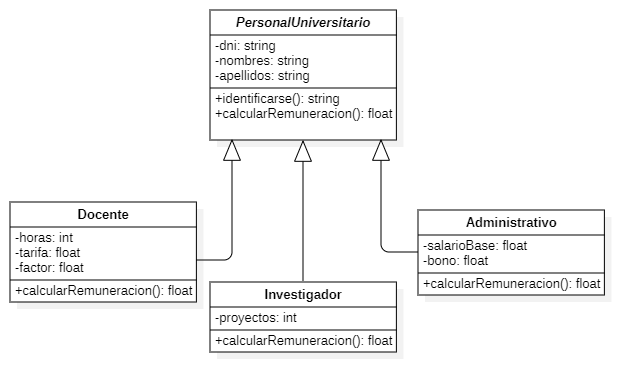

# Semana 4: Interfaces, clases Abstractas y Composición frente a Herencia

In [ ]:
# ── Práctica S4 — Actividad 1: Sistema de Notificaciones ───────────────
from abc import ABC, abstractmethod
from typing import Protocol, runtime_checkable


# Interfaz pura con ABC
class INotificador(ABC):
    @abstractmethod
    def enviar(self, destinatario: str, mensaje: str) -> bool: ...

    @abstractmethod
    def es_disponible(self) -> bool: ...

    @property
    @abstractmethod
    def nombre(self) -> str: ...


# Interfaz con Protocol (duck typing estructural — sin herencia requerida)
@runtime_checkable
class ProtocolNotificador(Protocol):
    def enviar(self, destinatario: str, mensaje: str) -> bool: ...

    def es_disponible(self) -> bool: ...


class NotificadorEmail(INotificador):
    def __init__(self, servidor_smtp: str, puerto: int = 587):
        self._servidor = servidor_smtp
        self._puerto = puerto
        self._activo = True

    @property
    def nombre(self) -> str:
        return f"Email ({self._servidor})"

    def es_disponible(self) -> bool:
        return self._activo

    def enviar(self, dest: str, msg: str) -> bool:
        # Simular envío (imprimir el mensaje, retornar True)
        print(f"[EMAIL -> {dest}]: {msg[:50]}...")
        return True


class NotificadorSMS(INotificador):
    MAX_CHARS = 160

    def __init__(self, proveedor: str):
        self._proveedor = proveedor
        self._activo = True

    @property
    def nombre(self) -> str:
        return f"SMS ({self._proveedor})"

    def es_disponible(self) -> bool:
        return self._activo

    def enviar(self, dest: str, msg: str) -> bool:
        if len(msg) > self.MAX_CHARS:
            raise ValueError(f"SMS excede {self.MAX_CHARS} caracteres")
        print(f"[SMS -> {dest}]: {msg}")
        return True


class SistemaAlertas:
    """Usa composición — no sabe qué tipo de notificador usa."""

    def __init__(self, notificadores: list[INotificador]):
        if not notificadores:
            raise ValueError("Se requiere al menos un notificador")
        self._notificadores = list(notificadores)

    def agregar_notificador(self, n: INotificador) -> None:
        self._notificadores.append(n)

    def alertar(self, dest: str, mensaje: str) -> int:
        """Envía la alerta por TODOS los canales disponibles."""
        enviados = 0
        for n in self._notificadores:
            if n.es_disponible():
                try:
                    if n.enviar(dest, mensaje):
                        enviados += 1
                except Exception as e:
                    print(f"Error en {n.nombre}: {e}")
        return enviados


# ── Pruebas ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    sistema = SistemaAlertas([
        NotificadorEmail("smtp.unap.edu.pe"),
        NotificadorSMS("Movistar"),
    ])

    enviados = sistema.alertar(
        "jmamani@unap.edu.pe",
        "ALERTA: Temperatura del Lago Titicaca supera 18°C",
    )
    print(f"\nAlerta enviada por {enviados} canales.")

    # Verificar que funciona con cualquier INotificador (LSP + composición)
    assert isinstance(sistema._notificadores[0], INotificador)
    assert isinstance(sistema._notificadores[0], ProtocolNotificador)

[EMAIL -> jmamani@unap.edu.pe]: ALERTA: Temperatura del Lago Titicaca supera 18°C...
[SMS -> jmamani@unap.edu.pe]: ALERTA: Temperatura del Lago Titicaca supera 18°C

Alerta enviada por 2 canales.


In [ ]:
# ── Práctica S4 — Actividad 2: Sistema de Reportes con Composición ──────
from abc import ABC, abstractmethod


class Exportador(ABC):
    @abstractmethod
    def exportar(self, contenido: str, ruta: str) -> None:
        ...

    @property
    @abstractmethod
    def extension(self) -> str:
        ...


class Firmador(ABC):
    @abstractmethod
    def firmar(self, ruta: str) -> str:
        """Retorna ruta del archivo firmado."""
        ...


class ExportadorCSV(Exportador):
    @property
    def extension(self) -> str:
        return ".csv"

    def exportar(self, contenido: str, ruta: str) -> None:
        print(f"[CSV] Exportando a {ruta}{self.extension}")
        # En un sistema real: escribir el archivo en disco


class ExportadorJSON(Exportador):
    @property
    def extension(self) -> str:
        return ".json"

    def exportar(self, contenido: str, ruta: str) -> None:
        print(f"[JSON] Exportando a {ruta}{self.extension}")


class FirmadorDigital(Firmador):
    def __init__(self, clave: str):
        self._clave = clave

    def firmar(self, ruta: str) -> str:
        ruta_firmada = ruta + ".signed"
        print(f"[FIRMA] Firmando {ruta} -> {ruta_firmada}")
        return ruta_firmada


class GeneradorReporte:
    """Depende de abstracciones — no de implementaciones concretas."""

    def __init__(self, exportador: Exportador, firmador: Firmador | None = None):
        self._exportador = exportador
        self._firmador = firmador

    # ---- Inyección de dependencia en tiempo de ejecución ---------------
    def cambiar_exportador(self, exp: Exportador) -> None:
        self._exportador = exp

    def generar(self, datos: dict, nombre: str) -> str:
        contenido = self._formatear(datos)
        ruta_base = f"reportes/{nombre}"

        # 1. Exportar con la estrategia actual
        self._exportador.exportar(contenido, ruta_base)
        ruta_final = ruta_base + self._exportador.extension

        # 2. Firmar si hay un firmador configurado
        if self._firmador:
            ruta_final = self._firmador.firmar(ruta_final)

        return ruta_final

    def _formatear(self, datos: dict) -> str:
        return ", ".join(f"{k}={v}" for k, v in datos.items())


# ── Demostración ─────────────────────────────────────────────────────────
if __name__ == "__main__":
    datos_planilla = {"total_personal": 45, "monto_total": 185000.50}

    # 1. Reporte CSV sin firma
    gen = GeneradorReporte(ExportadorCSV())
    ruta = gen.generar(datos_planilla, "planilla_agosto")
    print(f"Generado: {ruta}\n")

    # 2. Cambiar exportador en tiempo de ejecución (sin modificar GeneradorReporte)
    gen.cambiar_exportador(ExportadorJSON())
    ruta = gen.generar(datos_planilla, "planilla_agosto")
    print(f"Generado: {ruta}\n")

    # 3. Reporte CSV con firma digital
    gen_firmado = GeneradorReporte(ExportadorCSV(), FirmadorDigital("clave_unap_2026"))
    ruta = gen_firmado.generar(datos_planilla, "planilla_firmada")
    print(f"Generado y firmado: {ruta}")

[CSV] Exportando a reportes/planilla_agosto.csv
Generado: reportes/planilla_agosto.csv

[JSON] Exportando a reportes/planilla_agosto.json
Generado: reportes/planilla_agosto.json

[CSV] Exportando a reportes/planilla_firmada.csv
[FIRMA] Firmando reportes/planilla_firmada.csv -> reportes/planilla_firmada.csv.signed
Generado y firmado: reportes/planilla_firmada.csv.signed


CÓDIGO REFACTORIZADO SEMANA 4

In [ ]:
# ============================================================================
# ACTIVIDAD 5: Proyecto Integrador Refactorizado (Interfaces + Composición + DI)
# ============================================================================
import json
from abc import ABC, abstractmethod
from typing import Any


# ── 1. Contrato de Interfaz (ABC con métodos abstractos) ────────────────────
class IAlmacenable(ABC):
    """Contrato abstracto de persistencia desacoplado de las entidades."""

    @abstractmethod
    def guardar(self, clave: str, datos: dict[str, Any]) -> bool:
        """Guarda un registro asociado a una clave única."""
        ...

    @abstractmethod
    def recuperar(self, clave: str) -> dict[str, Any] | None:
        """Recupera un registro por su clave."""
        ...

    @abstractmethod
    def listar_todos(self) -> list[dict[str, Any]]:
        """Retorna todos los registros guardados."""
        ...


# ── 2. Implementaciones Concretas de la Interfaz ────────────────────────────
class RepositorioMemoria(IAlmacenable):
    """Implementación volátil ideal para pruebas unitarias sin dependencias externas."""

    def __init__(self):
        self._almacen: dict[str, dict[str, Any]] = {}

    def guardar(self, clave: str, datos: dict[str, Any]) -> bool:
        self._almacen[clave] = datos.copy()
        return True

    def recuperar(self, clave: str) -> dict[str, Any] | None:
        return self._almacen.get(clave)

    def listar_todos(self) -> list[dict[str, Any]]:
        return list(self._almacen.values())


class RepositorioJSON(IAlmacenable):
    """Implementación de persistencia real en archivo JSON."""

    def __init__(self, ruta_archivo: str = "personal_unap.json"):
        self._ruta = ruta_archivo
        self._cache: dict[str, dict[str, Any]] = {}
        self._cargar()

    def _cargar(self) -> None:
        try:
            with open(self._ruta, "r", encoding="utf-8") as f:
                self._cache = json.load(f)
        except (FileNotFoundError, json.JSONDecodeError):
            self._cache = {}

    def _sincronizar_disco(self) -> None:
        with open(self._ruta, "w", encoding="utf-8") as f:
            json.dump(self._cache, f, indent=2, ensure_ascii=False)

    def guardar(self, clave: str, datos: dict[str, Any]) -> bool:
        self._cache[clave] = datos
        self._sincronizar_disco()
        return True

    def recuperar(self, clave: str) -> dict[str, Any] | None:
        return self._cache.get(clave)

    def listar_todos(self) -> list[dict[str, Any]]:
        return list(self._cache.values())


# ── 3. Jerarquía del Personal Universitario (Semanas 1-3) ───────────────────
class PersonalUniversitario(ABC):
    TARIFA_HORA_BASE = 75.0

    def __init__(self, dni: str, nombres: str, apellidos: str):
        self.__dni = self._validar_dni(dni)
        self._nombres = nombres
        self._apellidos = apellidos

    @staticmethod
    def _validar_dni(dni: str) -> str:
        if not (dni.isdigit() and len(dni) == 8):
            raise ValueError(f"DNI inválido: {dni!r}")
        return dni

    @property
    def dni(self) -> str:
        return self.__dni

    @property
    def nombre_completo(self) -> str:
        return f"{self._apellidos}, {self._nombres}"

    @abstractmethod
    def calcular_remuneracion(self) -> float:
        ...

    def a_diccionario(self) -> dict[str, Any]:
        return {
            "dni": self.__dni,
            "nombre_completo": self.nombre_completo,
            "tipo": self.__class__.__name__,
            "remuneracion": self.calcular_remuneracion(),
        }

    def __str__(self) -> str:
        return f"{self.nombre_completo} (DNI: {self.__dni}) → S/ {self.calcular_remuneracion():.2f}"


class Docente(PersonalUniversitario):
    FACTORES = {"Auxiliar": 1.0, "Asociado": 1.4, "Principal": 1.8}

    def __init__(
        self,
        dni: str,
        nombres: str,
        apellidos: str,
        horas: int,
        categoria: str,
    ):
        super().__init__(dni, nombres, apellidos)
        if horas <= 0 or horas > 40:
            raise ValueError("Horas deben estar en [1, 40]")
        if categoria not in self.FACTORES:
            raise ValueError(f"Categoría inválida: {categoria}")
        self._horas = horas
        self._categoria = categoria

    def calcular_remuneracion(self) -> float:
        return (
            self._horas * self.TARIFA_HORA_BASE * self.FACTORES[self._categoria]
        )


class Administrativo(PersonalUniversitario):
    def __init__(
        self,
        dni: str,
        nombres: str,
        apellidos: str,
        salario_base: float,
        bono: float = 0.0,
    ):
        super().__init__(dni, nombres, apellidos)
        if salario_base <= 0:
            raise ValueError("El salario base debe ser mayor a 0")
        self._salario_base = salario_base
        self._bono = bono

    def calcular_remuneracion(self) -> float:
        return self._salario_base + self._bono


class Investigador(PersonalUniversitario):
    REMUNERACION_POR_PROYECTO = 1500.0

    def __init__(self, dni: str, nombres: str, apellidos: str, proyectos: int):
        super().__init__(dni, nombres, apellidos)
        if proyectos < 1:
            raise ValueError("Debe tener al menos 1 proyecto")
        self._proyectos = proyectos

    def calcular_remuneracion(self) -> float:
        return self._proyectos * self.REMUNERACION_POR_PROYECTO


# ── 4. Clase Consumidora con Composición e Inyección de Dependencias ────────
class GestorPersonalUniversitario:
    """Usa Composición (HAS-A) e Inyección de Dependencias (DIP).

    Recibe cualquier implementación de IAlmacenable sin conocer detalles de
    disco/memoria.
    """

    def __init__(self, repositorio: IAlmacenable):
        # Inyección de dependencia en el constructor
        self._repositorio = repositorio
        self._personal: list[PersonalUniversitario] = []

    def registrar_personal(self, persona: PersonalUniversitario) -> None:
        self._personal.append(persona)
        # Delegación por composición al contrato de interfaz
        self._repositorio.guardar(persona.dni, persona.a_diccionario())

    def calcular_total_planilla(self) -> float:
        return sum(p.calcular_remuneracion() for p in self._personal)

    def consultar_por_dni(self, dni: str) -> dict[str, Any] | None:
        return self._repositorio.recuperar(dni)

    def emitir_reporte_planilla(self) -> None:
        print("=" * 65)
        print("REPORTE OFICIAL DE PLANILLA — UNAP PUNO (COMPOSICIÓN + DI)")
        print("=" * 65)
        for p in self._personal:
            print(f"- {p}")
        print("-" * 65)
        print(
            f"TOTAL PLANILLA GENERAL: S/ {self.calcular_total_planilla():.2f}"
        )
        print(f"REGISTROS EN ALMACÉN:  {len(self._repositorio.listar_todos())}")
        print("=" * 65)


# ── 5. Demostración y Pruebas ───────────────────────────────────────────────
if __name__ == "__main__":
    print(
        "--- Test 1: Inyección con RepositorioMemoria (Mock para Pruebas Unitarias) ---"
    )
    repo_mock = RepositorioMemoria()
    gestor_mock = GestorPersonalUniversitario(repositorio=repo_mock)

    docente1 = Docente(
        "12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"
    )
    admin1 = Administrativo("34567890", "Pedro", "Huanca Lazo", 2800.0, 350.0)

    gestor_mock.registrar_personal(docente1)
    gestor_mock.registrar_personal(admin1)

    assert repo_mock.recuperar("12345678") is not None
    assert repo_mock.recuperar("12345678")["tipo"] == "Docente"
    assert (
        gestor_mock.calcular_total_planilla()
        == (16 * 75.0 * 1.4) + 2800.0 + 350.0
    )
    print("✅ Prueba unitaria con Mock en memoria aprobada exitosamente.")

    print(
        "\n--- Test 2: Inyección con RepositorioJSON (Persistencia en Archivo) ---"
    )
    repo_json = RepositorioJSON("planilla_unap_2026.json")
    gestor_prod = GestorPersonalUniversitario(repositorio=repo_json)

    docente2 = Docente(
        "23456789", "María Elena", "Quispe Torres", 12, "Principal"
    )
    investigador1 = Investigador("45678901", "Ana Lucía", "Flores Ramos", 2)

    gestor_prod.registrar_personal(docente1)
    gestor_prod.registrar_personal(docente2)
    gestor_prod.registrar_personal(admin1)
    gestor_prod.registrar_personal(investigador1)

    gestor_prod.emitir_reporte_planilla()

    registro = repo_json.recuperar("45678901")
    print(f"\nVerificación de registro recuperado: {registro}")
    assert registro["remuneracion"] == 3000.0
    print(" Persistencia JSON y Composición verificadas al 100%.")

--- Test 1: Inyección con RepositorioMemoria (Mock para Pruebas Unitarias) ---
✅ Prueba unitaria con Mock en memoria aprobada exitosamente.

--- Test 2: Inyección con RepositorioJSON (Persistencia en Archivo) ---
REPORTE OFICIAL DE PLANILLA — UNAP PUNO (COMPOSICIÓN + DI)
- Mamani Quispe, Juan Carlos (DNI: 12345678) → S/ 1680.00
- Quispe Torres, María Elena (DNI: 23456789) → S/ 1620.00
- Huanca Lazo, Pedro (DNI: 34567890) → S/ 3150.00
- Flores Ramos, Ana Lucía (DNI: 45678901) → S/ 3000.00
-----------------------------------------------------------------
TOTAL PLANILLA GENERAL: S/ 9450.00
REGISTROS EN ALMACÉN:  4

Verificación de registro recuperado: {'dni': '45678901', 'nombre_completo': 'Flores Ramos, Ana Lucía', 'tipo': 'Investigador', 'remuneracion': 3000.0}
 Persistencia JSON y Composición verificadas al 100%.


DIAGRAMA ACTUALIZADO - SEMANA 4
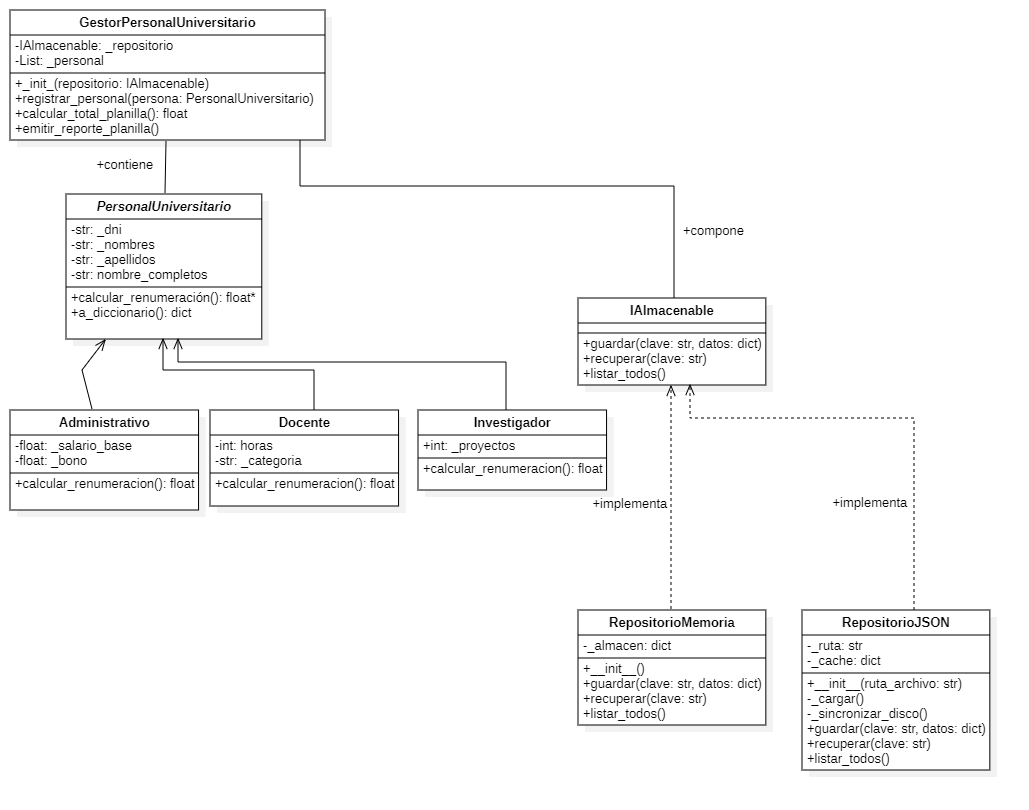

# Semana 5:Manejo de Excepciones y Diseño por Contrato

In [ ]:
# -- excepciones.py - Jerarquia de excepciones de dominio en Python 3.12 --
from __future__ import annotations


# -- 1. Raiz del dominio academico ------------------------------------------
class ErrorAcademico(Exception):
    """Raiz de todas las excepciones del dominio academico."""

    def __init__(self, mensaje: str, contexto: dict | None = None):
        super().__init__(mensaje)
        # contexto: datos adicionales del error (campo, valor, entidad, etc.)
        self.contexto: dict = contexto or {}

    def __str__(self) -> str:
        base = super().__str__()
        if self.contexto:
            ctx = ", ".join(f"{k}={v!r}" for k, v in self.contexto.items())
            return f"{base} <- contexto: {{{ctx}}}"
        return base


# -- 2. Primer nivel: error de validacion -----------------------------------
class ErrorValidacion(ErrorAcademico):
    """Datos de entrada que violan las reglas del dominio."""


# -- 3. Segundo nivel: especializaciones de validacion ---------------------
class ErrorCalificacion(ErrorValidacion):
    """Nota fuera del rango [0, 20] del sistema vigesimal."""

    def __init__(self, valor: float, campo: str = "nota"):
        super().__init__(
            f"Calificacion {valor} fuera de [0, 20]",
            contexto={"campo": campo, "valor": valor, "rango": "[0, 20]"}
        )
        self.valor_invalido = valor


class ErrorMatriculaDuplicada(ErrorValidacion):
    """Estudiante ya registrado previamente en el curso."""

    def __init__(self, codigo: int | str):
        codigo_str = str(codigo)
        super().__init__(
            f"Estudiante con codigo {codigo_str} ya se encuentra matriculado",
            contexto={"codigo": codigo_str, "entidad": "Matricula"}
        )
        self.codigo_estudiante = codigo_str


# -- 4. Errores de dominio adicionales --------------------------------------
class ErrorCapacidad(ErrorAcademico):
    """Operacion que excede el limite de capacidad permitido."""

    def __init__(self, actual: int, maximo: int, entidad: str):
        super().__init__(
            f"{entidad}: capacidad agotada ({actual}/{maximo})",
            contexto={"actual": actual, "maximo": maximo, "entidad": entidad}
        )
        self.actual = actual
        self.maximo = maximo
        self.entidad = entidad


class ErrorRecursoNoEncontrado(ErrorAcademico):
    """Entidad buscada que no existe en el repositorio."""

    def __init__(self, tipo: str, identificador):
        super().__init__(
            f"{tipo} con id={identificador!r} no encontrado",
            contexto={"tipo": tipo, "id": identificador}
        )
        self.tipo = tipo
        self.identificador = identificador


# -- Funciones de logica de negocio -----------------------------------------
def registrar_nota(valor: float, campo: str = "nota") -> None:
    """Valida y registra una calificacion; lanza ErrorCalificacion si es invalida."""
    if not (0.0 <= valor <= 20.0):
        raise ErrorCalificacion(valor, campo)


def validar_matricula(codigo: int, matriculados: list[int]) -> None:
    """Lanza ErrorMatriculaDuplicada si el codigo ya existe en la lista."""
    if codigo in matriculados:
        raise ErrorMatriculaDuplicada(codigo)


def cargar_nota_desde_archivo(ruta: str, codigo: int) -> float:
    """
    Carga nota desde un archivo.
    Usa 'raise ... from ...' para encadenar la excepcion original
    (FileNotFoundError o ValueError) con la excepcion del dominio.
    """
    try:
        with open(ruta, "r", encoding="utf-8") as f:
            contenido = f.read().strip()
            return float(contenido)
    except FileNotFoundError as causa:
        # Encadenamiento con raise ... from ... preserva la causa original
        raise ErrorRecursoNoEncontrado("Archivo de notas", ruta) from causa
    except ValueError as causa:
        # Encadenamiento con raise ... from ...
        raise ErrorValidacion(
            f"Formato no numerico en archivo para estudiante {codigo}",
            contexto={"ruta": ruta, "codigo": codigo, "contenido": contenido}
        ) from causa


# -- Demostracion de captura selectiva y contexto ---------------------------
def probar_caso(descripcion: str, accion):
    print("\n" + "-" * 55)
    print(f"Ejecutando: {descripcion}")
    print("-" * 55)
    try:
        accion()
        print("-> Operacion completada con EXITO (sin excepciones).")
    # Captura selectiva en orden jerarquico correcto
    except ErrorMatriculaDuplicada as e:
        print("[CAPTURADO: ErrorMatriculaDuplicada]")
        print(f"  Mensaje   : {e}")
        print(f"  Contexto  : {e.contexto}")
        print(f"  Codigo    : {e.codigo_estudiante}")
    except ErrorCalificacion as e:
        print("[CAPTURADO: ErrorCalificacion]")
        print(f"  Mensaje   : {e}")
        print(f"  Contexto  : {e.contexto}")
        print(f"  Valor     : {e.valor_invalido}")
    except ErrorValidacion as e:
        print("[CAPTURADO: ErrorValidacion (generico)]")
        print(f"  Mensaje   : {e}")
        print(f"  Contexto  : {e.contexto}")
        if e.__cause__:
            print(f"  Causa raiz: {type(e.__cause__).__name__} -> {e.__cause__}")
    except ErrorRecursoNoEncontrado as e:
        print("[CAPTURADO: ErrorRecursoNoEncontrado]")
        print(f"  Mensaje   : {e}")
        print(f"  Contexto  : {e.contexto}")
        if e.__cause__:
            print(f"  Causa raiz: {type(e.__cause__).__name__} -> {e.__cause__}")
    except ErrorAcademico as e:
        print("[CAPTURADO: ErrorAcademico (raiz de dominio)]")
        print(f"  Mensaje   : {e}")
        print(f"  Contexto  : {e.contexto}")
    except Exception as e:
        print(f"[CAPTURADO: Excepcion inesperada]: {type(e).__name__} -> {e}")


def main():
    print("=" * 55)
    print("  DEMOSTRACION PARTE B - PYTHON 3.12 (EXCEPCIONES)")
    print("=" * 55)

    matriculados = [2021001, 2021002, 2021003]

    # Caso 1: ErrorCalificacion fuera de rango
    probar_caso(
        "Registrar nota invalida (25.0 en POO II)",
        lambda: registrar_nota(25.0, "POO II")
    )

    # Caso 2: ErrorMatriculaDuplicada
    probar_caso(
        "Validar matricula de estudiante ya existente (2021002)",
        lambda: validar_matricula(2021002, matriculados)
    )

    # Caso 3: Matricula exitosa (sin excepcion)
    def matricula_exitosa():
        nuevo = 2021004
        validar_matricula(nuevo, matriculados)
        matriculados.append(nuevo)
        print(f"  Estudiante {nuevo} matriculado exitosamente.")

    probar_caso(
        "Validar y matricular estudiante nuevo (2021004)",
        matricula_exitosa
    )

    # Caso 4: Encadenamiento con raise ... from ... (Archivo no encontrado)
    probar_caso(
        "Cargar nota desde archivo inexistente (raise ... from ...)",
        lambda: cargar_nota_desde_archivo("nota_inexistente.txt", 2021001)
    )

    # Caso 5: Error de capacidad (raiz de dominio)
    def lanzar_capacidad():
        raise ErrorCapacidad(40, 40, "Laboratorio Python")

    probar_caso(
        "Exceder capacidad maxima de aula",
        lanzar_capacidad
    )


if __name__ == "__main__":
    main()

  DEMOSTRACION PARTE B - PYTHON 3.12 (EXCEPCIONES)

-------------------------------------------------------
Ejecutando: Registrar nota invalida (25.0 en POO II)
-------------------------------------------------------
[CAPTURADO: ErrorCalificacion]
  Mensaje   : Calificacion 25.0 fuera de [0, 20] <- contexto: {campo='POO II', valor=25.0, rango='[0, 20]'}
  Contexto  : {'campo': 'POO II', 'valor': 25.0, 'rango': '[0, 20]'}
  Valor     : 25.0

-------------------------------------------------------
Ejecutando: Validar matricula de estudiante ya existente (2021002)
-------------------------------------------------------
[CAPTURADO: ErrorMatriculaDuplicada]
  Mensaje   : Estudiante con codigo 2021002 ya se encuentra matriculado <- contexto: {codigo='2021002', entidad='Matricula'}
  Contexto  : {'codigo': '2021002', 'entidad': 'Matricula'}
  Codigo    : 2021002

-------------------------------------------------------
Ejecutando: Validar y matricular estudiante nuevo (2021004)
---------------

# SEMANA 6 — Colecciones, Templates STL y Repositorios Genéricos

In [ ]:
# -*- coding: utf-8 -*-
"""
repositorio.py — Repositorio genérico con TypeVar y Generic en Python 3.12+
"""
from typing import TypeVar, Generic, Callable, Iterator, Any
from functools import reduce

T = TypeVar("T")    # Tipo de la entidad
ID = TypeVar("ID")  # Tipo del identificador

class Repositorio(Generic[T, ID]):
    """
    Repositorio genérico en memoria para cualquier par (Entidad, TipoID).
    Usa un diccionario interno dict[ID, T] para acceso O(1).
    """
    def __init__(self, fn_id: Callable[[T], ID]) -> None:
        """
        fn_id: Función o lambda que extrae el identificador ID de una entidad T.
        """
        self._fn_id: Callable[[T], ID] = fn_id
        self._datos: dict[ID, T] = {}

    # ── CRUD Básico ──────────────────────────────────────────────────────────
    def guardar(self, entidad: T) -> None:
        """Guarda o sobreescribe la entidad indexada por su ID."""
        self._datos[self._fn_id(entidad)] = entidad

    def buscar(self, id_: ID) -> T | None:
        """Retorna la entidad asociada al ID o None si no existe."""
        return self._datos.get(id_)

    def eliminar(self, id_: ID) -> bool:
        """Elimina la entidad por su ID. Retorna True si existía y fue eliminada."""
        return bool(self._datos.pop(id_, None))

    # ── Consultas ────────────────────────────────────────────────────────────
    def todos(self) -> list[T]:
        """Retorna una lista con copia de todas las entidades."""
        return list(self._datos.values())

    def filtrar(self, pred: Callable[[T], bool]) -> list[T]:
        """Retorna una lista con las entidades que satisfacen el predicado."""
        return [e for e in self._datos.values() if pred(e)]

    def ordenar(self, key: Callable[[T], Any], reverse: bool = False) -> list[T]:
        """Retorna una lista ordenada según la función clave dada."""
        return sorted(self._datos.values(), key=key, reverse=reverse)

    def acumular(self, inicial: Any, f: Callable[[Any, T], Any]) -> Any:
        """Reduce todas las entidades acumulando mediante la función f."""
        return reduce(f, self._datos.values(), inicial)

    # ── Protocolo Python (Dunder methods) ─────────────────────────────────────
    def __len__(self) -> int:
        """Permite usar len(repo)."""
        return len(self._datos)

    def __contains__(self, id_: ID) -> bool:
        """Permite usar `id_ in repo`."""
        return id_ in self._datos

    def __iter__(self) -> Iterator[T]:
        """Permite iterar directamente sobre las entidades: `for e in repo:`."""
        return iter(self._datos.values())

    # ── Métodos Adicionales Requeridos en Actividad 2 ─────────────────────────
    def contar(self, pred: Callable[[T], bool]) -> int:
        """Cuenta cuántos elementos satisfacen el predicado."""
        return sum(1 for e in self._datos.values() if pred(e))

    def existe(self, id_: ID) -> bool:
        """Verifica si existe una entidad con el identificador dado."""
        return id_ in self._datos

    def primero(self, pred: Callable[[T], bool]) -> T | None:
        """Retorna el primer elemento que satisface el predicado, o None si no hay ninguno."""
        return next((e for e in self._datos.values() if pred(e)), None)

    # ── Análisis y Estadísticas ──────────────────────────────────────────────
    def estadisticas(self, attr: str) -> dict[str, Any]:
        """Calcula min, max, promedio y conteo de un atributo numérico de las entidades."""
        valores = [getattr(e, attr) for e in self._datos.values()]
        if not valores:
            return {"min": None, "max": None, "promedio": None, "n": 0}
        return {
            "min": min(valores),
            "max": max(valores),
            "promedio": sum(valores) / len(valores),
            "n": len(valores)
        }


In [ ]:
# -*- coding: utf-8 -*-
"""
actividad2_main.py — Demostración de Repositorio genérico en Python con consultas de dominio y estadísticas
"""
from dataclasses import dataclass
# Se remueve 'from repositorio import Repositorio' porque la clase ya está definida en el kernel.

@dataclass
class Estudiante:
    codigo: int
    nombre: str
    ppa: float
    escuela: str

def main() -> None:
    print("=" * 65)
    print("ACTIVIDAD 2: REPOSITORIO PYTHON GENÉRICO + CONSULTAS DE DOMINIO")
    print("=" * 65)

    # 1. Instanciación con lambda extractora de ID
    repo: Repositorio[Estudiante, int] = Repositorio(lambda e: e.codigo)

    # Guardar estudiantes
    estudiantes = [
        Estudiante(1001, "Juan Carlos Mamani", 15.2, "Ing. Sistemas"),
        Estudiante(1002, "Maria Elena Quispe", 18.5, "Ing. Sistemas"),
        Estudiante(1003, "Pedro Flores", 9.8, "Ciencias Comp."),
        Estudiante(1004, "Ana Torres", 13.0, "Ing. Sistemas"),
        Estudiante(1005, "Carlos Condori", 16.8, "Ing. Sistemas"),
        Estudiante(1006, "Lucia Morales", 14.7, "Ciencias Comp."),
    ]
    for e in estudiantes:
        repo.guardar(e)

    print(f"\nTotal estudiantes registrados (len): {len(repo)}")

    # Probar existe() y __contains__
    print(f"[existe(1002)]: {repo.existe(1002)}")
    print(f"[1002 in repo]: {1002 in repo}")
    print(f"[existe(9999)]: {repo.existe(9999)}")

    # Probar buscar()
    buscado = repo.buscar(1001)
    if buscado:
        print(f"[buscar(1001)]: Encontrado -> {buscado.nombre} (PPA: {buscado.ppa})")

    # Probar contar()
    n_destacados = repo.contar(lambda e: e.ppa >= 14.0)
    print(f"[contar(PPA >= 14.0)]: {n_destacados} estudiantes")

    # Probar primero()
    primer_cc = repo.primero(lambda e: e.escuela == "Ciencias Comp.")
    if primer_cc:
        print(f"[primero(escuela == 'Ciencias Comp.')]: {primer_cc.nombre} (PPA: {primer_cc.ppa})")

    # ── 3 CONSULTAS DE DOMINIO (REQUERIDAS) ───────────────────────────────────
    print("\n" + "-" * 65)
    print(">>> 3 CONSULTAS DE DOMINIO ACADÉMICO:")
    print("-" * 65)

    # Consulta 1: Estudiantes con PPA >= 14 en Ing. Sistemas
    destacados_sis = repo.filtrar(
        lambda e: e.ppa >= 14.0 and e.escuela == "Ing. Sistemas"
    )
    print(f"\n[Consulta 1] Destacados en Ing. Sistemas (PPA >= 14.0): {len(destacados_sis)}")
    for e in destacados_sis:
        print(f"  * [{e.codigo}] {e.nombre:<22} | PPA: {e.ppa:.2f}")

    # Consulta 2: Ranking completo por PPA
    ranking = repo.ordenar(key=lambda e: e.ppa, reverse=True)
    print("\n[Consulta 2] Ranking completo por PPA descendente:")
    for i, e in enumerate(ranking, 1):
        print(f"  {i}. [{e.codigo}] {e.nombre:<22} — {e.ppa:.2f} ({e.escuela})")

    # Consulta 3: Estadísticas por escuela usando comprensión de sets
    print("\n[Consulta 3] Estadísticas agrupadas por escuela:")
    escuelas = {e.escuela for e in repo}  # Set de escuelas únicas gracias a __iter__
    for esc in sorted(escuelas):
        alumnos = repo.filtrar(lambda e: e.escuela == esc)
        prom = sum(a.ppa for a in alumnos) / len(alumnos)
        print(f"  * Escuela '{esc}': {len(alumnos)} estudiantes | Promedio PPA: {prom:.2f}")

    # Protocolo iteración directa
    print("\n" + "-" * 65)
    print(">>> PROTOCOLO PYTHON (__iter__):")
    total_sistemas = sum(1 for e in repo if e.escuela == "Ing. Sistemas")
    print(f"Total directo iterando sobre repo (Ing. Sistemas): {total_sistemas}")

    # Estadísticas numéricas
    stats = repo.estadisticas("ppa")
    print(f"\n[Estadísticas globales PPA]:")
    print(f"  - Promedio : {stats['promedio']:.2f}")
    print(f"  - Máximo   : {stats['max']:.2f}")
    print(f"  - Mínimo   : {stats['min']:.2f}")
    print(f"  - Total (n): {stats['n']}")
    print("=" * 65)

if __name__ == "__main__":
    main()

ACTIVIDAD 2: REPOSITORIO PYTHON GENÉRICO + CONSULTAS DE DOMINIO

Total estudiantes registrados (len): 6
[existe(1002)]: True
[1002 in repo]: True
[existe(9999)]: False
[buscar(1001)]: Encontrado -> Juan Carlos Mamani (PPA: 15.2)
[contar(PPA >= 14.0)]: 4 estudiantes
[primero(escuela == 'Ciencias Comp.')]: Pedro Flores (PPA: 9.8)

-----------------------------------------------------------------
>>> 3 CONSULTAS DE DOMINIO ACADÉMICO:
-----------------------------------------------------------------

[Consulta 1] Destacados en Ing. Sistemas (PPA >= 14.0): 3
  * [1001] Juan Carlos Mamani     | PPA: 15.20
  * [1002] Maria Elena Quispe     | PPA: 18.50
  * [1005] Carlos Condori         | PPA: 16.80

[Consulta 2] Ranking completo por PPA descendente:
  1. [1002] Maria Elena Quispe     — 18.50 (Ing. Sistemas)
  2. [1005] Carlos Condori         — 16.80 (Ing. Sistemas)
  3. [1001] Juan Carlos Mamani     — 15.20 (Ing. Sistemas)
  4. [1006] Lucia Morales          — 14.70 (Ciencias Comp.)
  5. [1004

In [ ]:
# -*- coding: utf-8 -*-
"""
actividad3_python.py — Iteradores y estructuras en Python:
1. Generador ventana_deslizante
2. ColaAtencion con deque (FIFO)
3. Benchmark: deque.popleft() vs list.pop(0) con 10 000 elementos
"""
from collections import deque
from typing import Iterator, Any
import timeit

# ── 1. Generador ventana_deslizante ───────────────────────────────────────────
def ventana_deslizante(datos: list[Any], k: int) -> Iterator[list[Any]]:
    """
    Genera ventanas contiguas de tamaño k sobre una secuencia.
    Útil para cálculos en memoria eficiente (e.g. promedios móviles).
    """
    if k > len(datos):
        raise ValueError(f"Ventana k={k} mayor que datos={len(datos)}")
    for i in range(len(datos) - k + 1):
        yield datos[i : i + k]


# ── 2. ColaAtencion con deque (FIFO O(1)) ──────────────────────────────────────
class ColaAtencion:
    """
    Cola de atención FIFO para trámites o matrícula universitaria.
    deque garantiza append y popleft en O(1) amortizado, mientras que
    list.pop(0) es O(n) al desplazar todos los elementos restantes.
    """
    def __init__(self) -> None:
        self._cola: deque[Any] = deque()

    def encolar(self, elemento: Any) -> None:
        """Agrega un elemento al final de la cola: O(1)."""
        self._cola.append(elemento)

    def atender(self) -> Any | None:
        """Desencola y atiende el primer elemento de la cola: O(1)."""
        return self._cola.popleft() if self._cola else None

    def __len__(self) -> int:
        return len(self._cola)

    def __iter__(self) -> Iterator[Any]:
        return iter(self._cola)

    def __bool__(self) -> bool:
        return bool(self._cola)


# ── 3. Benchmarking deque.popleft() vs list.pop(0) ────────────────────────────
def benchmark_cola(n: int = 10_000) -> None:
    """
    Compara el tiempo de vaciar una estructura de n elementos
    usando deque.popleft() [O(1)] vs list.pop(0) [O(n)].
    """
    print(f"\n>>> 3. BENCHMARK: deque.popleft() vs list.pop(0) (N = {n:,}):")
    print("-" * 65)

    setup_deque = f"from collections import deque; d = deque(range({n}))"
    stmt_deque = "while d: d.popleft()"
    t_deque = timeit.timeit(stmt=stmt_deque, setup=setup_deque, number=10)

    setup_list = f"l = list(range({n}))"
    stmt_list = "while l: l.pop(0)"
    t_list = timeit.timeit(stmt=stmt_list, setup=setup_list, number=10)

    t_deque_ms = (t_deque / 10) * 1000
    t_list_ms = (t_list / 10) * 1000
    ratio = t_list_ms / t_deque_ms if t_deque_ms > 0 else 0

    print(f"  * deque.popleft() : {t_deque_ms:.4f} ms por corrida (O(1) por op)")
    print(f"  * list.pop(0)     : {t_list_ms:.4f} ms por corrida (O(n) por op)")
    print(f"  -> deque es {ratio:.2f}x veces más rápido que list.pop(0)")


def main() -> None:
    print("=================================================================")
    print("ACTIVIDAD 3 (Python): GENERADOR, COLA FIFO Y BENCHMARK")
    print("=================================================================")

    # 1. Demostración de ventana deslizante
    print("\n>>> 1. GENERADOR DE VENTANA DESLIZANTE (Promedios móviles):")
    print("-" * 65)
    calificaciones = [10.0, 14.5, 18.0, 12.5, 16.0, 11.0, 19.0]
    print(f"Calificaciones: {calificaciones}")
    print("Promedios móviles (ventana k=3):")
    for ventana in ventana_deslizante(calificaciones, k=3):
        prom = sum(ventana) / len(ventana)
        print(f"  {ventana} -> promedio: {prom:.2f}")

    # 2. Demostración de ColaAtencion FIFO
    print("\n>>> 2. COLA DE ATENCIÓN FIFO CON deque:")
    print("-" * 65)
    cola = ColaAtencion()
    estudiantes_cola = ["Juan Mamani", "Maria Quispe", "Pedro Flores", "Ana Torres", "Carlos Condori"]
    for est in estudiantes_cola:
        cola.encolar(est)

    print(f"Total en cola de espera: {len(cola)}")
    print("Atención por ventanilla en estricto orden de llegada:")
    ticket = 1
    while cola:
        atendido = cola.atender()
        print(f"  Turno #{ticket}: {atendido} (restan {len(cola)} en espera)")
        ticket += 1

    # 3. Benchmark
    benchmark_cola(10_000)
    print("\n" + "=" * 65)


if __name__ == "__main__":
    main()


ACTIVIDAD 3 (Python): GENERADOR, COLA FIFO Y BENCHMARK

>>> 1. GENERADOR DE VENTANA DESLIZANTE (Promedios móviles):
-----------------------------------------------------------------
Calificaciones: [10.0, 14.5, 18.0, 12.5, 16.0, 11.0, 19.0]
Promedios móviles (ventana k=3):
  [10.0, 14.5, 18.0] -> promedio: 14.17
  [14.5, 18.0, 12.5] -> promedio: 15.00
  [18.0, 12.5, 16.0] -> promedio: 15.50
  [12.5, 16.0, 11.0] -> promedio: 13.17
  [16.0, 11.0, 19.0] -> promedio: 15.33

>>> 2. COLA DE ATENCIÓN FIFO CON deque:
-----------------------------------------------------------------
Total en cola de espera: 5
Atención por ventanilla en estricto orden de llegada:
  Turno #1: Juan Mamani (restan 4 en espera)
  Turno #2: Maria Quispe (restan 3 en espera)
  Turno #3: Pedro Flores (restan 2 en espera)
  Turno #4: Ana Torres (restan 1 en espera)
  Turno #5: Carlos Condori (restan 0 en espera)

>>> 3. BENCHMARK: deque.popleft() vs list.pop(0) (N = 10,000):
---------------------------------------------

In [ ]:
# -*- coding: utf-8 -*-
"""
benchmark_python.py — Comparación empírica list vs dict vs set
"""
import timeit
import random

def benchmark(n: int) -> dict:
    datos = list(range(n))
    buscar = n // 2  # Buscar el elemento intermedio para consistencia
    datos_dict = dict.fromkeys(datos)
    datos_set = set(datos)

    # 5 000 búsquedas estándar; para 1 000 000 ajustamos muestras para rapidez
    reps = 5000 if n < 1_000_000 else 500
    factor = 1.0 if n < 1_000_000 else 10.0

    t_list = timeit.timeit(lambda: buscar in datos, number=reps) * factor
    t_dict = timeit.timeit(lambda: buscar in datos_dict, number=reps) * factor
    t_set  = timeit.timeit(lambda: buscar in datos_set, number=reps) * factor

    return {
        "n": n,
        "list_ms": t_list * 1000,
        "dict_ms": t_dict * 1000,
        "set_ms": t_set * 1000
    }

def main() -> None:
    print("=================================================================")
    print("BENCHMARK PYTHON 3.14: list vs dict vs set")
    print("=================================================================")
    print(f"{'N':>12} {'list (ms)':>15} {'dict (ms)':>15} {'set (ms)':>15}")
    print("-" * 62)

    for n in [1_000, 10_000, 100_000, 1_000_000]:
        r = benchmark(n)
        print(f"{r['n']:>12,} {r['list_ms']:>15.3f} {r['dict_ms']:>15.3f} {r['set_ms']:>15.3f}")

    print("=================================================================")

if __name__ == "__main__":
    main()


BENCHMARK PYTHON 3.14: list vs dict vs set
           N       list (ms)       dict (ms)        set (ms)
--------------------------------------------------------------
       1,000          30.161           0.455           0.518
      10,000         257.349           0.432           0.466
     100,000        2591.453           0.645           0.404
   1,000,000       29463.949           0.459           0.415


In [ ]:
# -*- coding: utf-8 -*-
"""
proyecto_integrador.py — Actividad 5: Integración de Repositorios Genéricos en Python 3.12+
"""
from dataclasses import dataclass
from typing import Optional
# Se comentan las importaciones externas ya que las clases residen en la memoria activa de este notebook
# from repositorio import Repositorio
# from actividad3_python import ColaAtencion

@dataclass
class Docente:
    dni: str
    nombres: str
    apellidos: str
    categoria: str  # "Auxiliar", "Asociado", "Principal"
    horas: int
    factor: float

    @property
    def nombre_completo(self) -> str:
        return f"{self.apellidos}, {self.nombres}"

    def calcular_remuneracion(self) -> float:
        tarifa_hora = 75.0
        return self.horas * tarifa_hora * self.factor


@dataclass
class Administrativo:
    dni: str
    nombres: str
    apellidos: str
    area: str
    salario_base: float
    bono: float = 0.0

    @property
    def nombre_completo(self) -> str:
        return f"{self.apellidos}, {self.nombres}"

    def calcular_remuneracion(self) -> float:
        return self.salario_base + self.bono


class SistemaGestionUNAP:
    """
    Sistema del Proyecto Integrador refactorizado para usar Repositorio[T, ID]
    como única capa de almacenamiento en memoria y ColaAtencion para trámites FIFO.
    """
    def __init__(self) -> None:
        # Repositorio Tipado 1: Docentes (ID: str = DNI)
        self.repo_docentes: Repositorio[Docente, str] = Repositorio(lambda d: d.dni)
        # Repositorio Tipado 2: Administrativos (ID: str = DNI)
        self.repo_administrativos: Repositorio[Administrativo, str] = Repositorio(lambda a: a.dni)
        # Cola de trámites FIFO (deque)
        self.cola_tramites: ColaAtencion = ColaAtencion()

    def registrar_docente(self, docente: Docente) -> None:
        self.repo_docentes.guardar(docente)

    def registrar_administrativo(self, administrativo: Administrativo) -> None:
        self.repo_administrativos.guardar(administrativo)

    def encolar_tramite(self, dni: str) -> None:
        self.cola_tramites.encolar(dni)

    def atender_tramite(self) -> Optional[str]:
        return self.cola_tramites.atender()

    # ── 5 CONSULTAS DE DOMINIO REQUERIDAS ────────────────────────────────────

    # 1. Filtrar: Docentes con dedicación a tiempo completo (horas >= 30)
    def docentes_tiempo_completo(self) -> list[Docente]:
        return self.repo_docentes.filtrar(lambda d: d.horas >= 30)

    # 2. Ordenar: Ranking de docentes por remuneración descendente
    def ranking_docentes(self) -> list[Docente]:
        return self.repo_docentes.ordenar(key=lambda d: d.calcular_remuneracion(), reverse=True)

    # 3. Filtrar: Personal administrativo con bono asignado
    def administrativos_con_bono(self) -> list[Administrativo]:
        return self.repo_administrativos.filtrar(lambda a: a.bono > 0)

    # 4. Acumular: Total de planilla exclusiva de docentes
    def total_planilla_docentes(self) -> float:
        return self.repo_docentes.acumular(
            0.0, lambda acc, d: acc + d.calcular_remuneracion()
        )

    # 5. Acumular: Total consolidado institucional (Docentes + Administrativos)
    def total_planilla_institucional(self) -> float:
        total_doc = self.total_planilla_docentes()
        total_adm = self.repo_administrativos.acumular(
            0.0, lambda acc, a: acc + a.calcular_remuneracion()
        )
        return total_doc + total_adm


def main() -> None:
    print("=" * 65)
    print("ACTIVIDAD 5 (Python): PROYECTO INTEGRADOR CON REPOSITORIOS GEN.")
    print("=" * 65)

    sistema = SistemaGestionUNAP()

    # Cargar datos de Docentes
    sistema.registrar_docente(Docente("70112233", "Carlos", "Mamani Quispe", "Principal", 40, 1.8))
    sistema.registrar_docente(Docente("70223344", "Elena", "Flores Coila", "Asociado", 35, 1.4))
    sistema.registrar_docente(Docente("70334455", "Ana", "Ramos Cutipa", "Auxiliar", 20, 1.0))
    sistema.registrar_docente(Docente("70445566", "Victor", "Paredes Choque", "Auxiliar", 15, 1.0))
    sistema.registrar_docente(Docente("70556677", "Marcos", "Condori Apaza", "Principal", 38, 1.8))

    # Cargar datos de Administrativos
    sistema.registrar_administrativo(Administrativo("80112233", "Rosa", "Quispe Mamani", "Recursos Humanos", 2800.0, 450.0))
    sistema.registrar_administrativo(Administrativo("80223344", "Juan", "Calsin Ticona", "Contabilidad", 3200.0, 0.0))
    sistema.registrar_administrativo(Administrativo("80334455", "Sonia", "Chura Pari", "Secretaria General", 2500.0, 300.0))
    sistema.registrar_administrativo(Administrativo("80445566", "David", "Huanca Gomez", "Informatica", 3500.0, 600.0))

    print(f"Docentes registrados        : {len(sistema.repo_docentes)}")
    print(f"Administrativos registrados : {len(sistema.repo_administrativos)}")

    print("\n" + "-" * 65)
    print(">>> EJECUCIÓN DE LAS 5 CONSULTAS DE DOMINIO (Python):")
    print("-" * 65)

    # 1. Consulta 1
    tc = sistema.docentes_tiempo_completo()
    print(f"\n[Consulta 1] Docentes a Tiempo Completo (Horas >= 30) [{len(tc)}]:")
    for d in tc:
        print(f"  * {d.nombre_completo:<25} | {d.horas} hrs | Cat: {d.categoria:<10} | S/ {d.calcular_remuneracion():.2f}")

    # 2. Consulta 2
    rank = sistema.ranking_docentes()
    print(f"\n[Consulta 2] Ranking Docentes por Remuneración Descendente:")
    for i, d in enumerate(rank, 1):
        print(f"  {i}. {d.nombre_completo:<25} | DNI: {d.dni} | S/ {d.calcular_remuneracion():.2f}")

    # 3. Consulta 3
    bonos = sistema.administrativos_con_bono()
    print(f"\n[Consulta 3] Personal Administrativo con Bono Especial [{len(bonos)}]:")
    for a in bonos:
        print(f"  * {a.nombre_completo:<25} | Área: {a.area:<20} | Bono: S/ {a.bono:.2f} | Total: S/ {a.calcular_remuneracion():.2f}")

    # 4. Consulta 4
    total_doc = sistema.total_planilla_docentes()
    print(f"\n[Consulta 4] Total Planilla Docentes (acumular): S/ {total_doc:.2f}")

    # 5. Consulta 5
    total_inst = sistema.total_planilla_institucional()
    print(f"\n[Consulta 5] Total Planilla Institucional (Docentes + Admins): S/ {total_inst:.2f}")

    # Flujo de atención de trámites
    print("\n" + "-" * 65)
    print(">>> FLUJO DE ATENCIÓN CON COLA FIFO (deque):")
    print("-" * 65)
    sistema.encolar_tramite("70112233")
    sistema.encolar_tramite("80112233")
    sistema.encolar_tramite("70556677")
    sistema.encolar_tramite("80445566")

    print(f"Trámites en cola pendientes: {len(sistema.cola_tramites)}")
    t = 1
    while sistema.cola_tramites:
        dni = sistema.atender_tramite()
        if not dni:
            break
        persona = sistema.repo_docentes.buscar(dni) or sistema.repo_administrativos.buscar(dni)
        desc = persona.nombre_completo if persona else "Desconocido"
        rol = "Docente" if isinstance(persona, Docente) else "Administrativo"
        print(f"  Atendiendo Turno #{t}: DNI {dni} -> {desc} ({rol})")
        t += 1

    print("=" * 65)

if __name__ == "__main__":
    main()

ACTIVIDAD 5 (Python): PROYECTO INTEGRADOR CON REPOSITORIOS GEN.
Docentes registrados        : 5
Administrativos registrados : 4

-----------------------------------------------------------------
>>> EJECUCIÓN DE LAS 5 CONSULTAS DE DOMINIO (Python):
-----------------------------------------------------------------

[Consulta 1] Docentes a Tiempo Completo (Horas >= 30) [3]:
  * Mamani Quispe, Carlos     | 40 hrs | Cat: Principal  | S/ 5400.00
  * Flores Coila, Elena       | 35 hrs | Cat: Asociado   | S/ 3675.00
  * Condori Apaza, Marcos     | 38 hrs | Cat: Principal  | S/ 5130.00

[Consulta 2] Ranking Docentes por Remuneración Descendente:
  1. Mamani Quispe, Carlos     | DNI: 70112233 | S/ 5400.00
  2. Condori Apaza, Marcos     | DNI: 70556677 | S/ 5130.00
  3. Flores Coila, Elena       | DNI: 70223344 | S/ 3675.00
  4. Ramos Cutipa, Ana         | DNI: 70334455 | S/ 1500.00
  5. Paredes Choque, Victor    | DNI: 70445566 | S/ 1125.00

[Consulta 3] Personal Administrativo con Bono Especia

In [ ]:
# -*- coding: utf-8 -*-
"""
test_proyecto.py — Suite de pruebas automatizadas con pytest para Repositorio y Proyecto Integrador
"""
import pytest
# Se comentan las importaciones externas ya que las clases residen en la memoria activa de este notebook
# from repositorio import Repositorio
# from actividad3_python import ColaAtencion, ventana_deslizante
# from proyecto_integrador import Docente, Administrativo, SistemaGestionUNAP

# ── Pruebas del Repositorio Genérico ──────────────────────────────────────────
def test_repositorio_crud():
    repo: Repositorio[Docente, str] = Repositorio(lambda d: d.dni)
    assert len(repo) == 0

    doc1 = Docente("11112222", "Juan", "Perez", "Auxiliar", 20, 1.0)
    repo.guardar(doc1)
    assert len(repo) == 1
    assert repo.existe("11112222")
    assert not repo.existe("99999999")

    # buscar
    recuperado = repo.buscar("11112222")
    assert recuperado is not None
    assert recuperado.nombre_completo == "Perez, Juan"

    # eliminar
    assert repo.eliminar("11112222")
    assert not repo.existe("11112222")
    assert len(repo) == 0
    assert not repo.eliminar("11112222")


def test_repositorio_consultas():
    repo: Repositorio[Docente, str] = Repositorio(lambda d: d.dni)
    repo.guardar(Docente("111", "A", "Doc1", "Auxiliar", 10, 1.0))
    repo.guardar(Docente("222", "B", "Doc2", "Asociado", 30, 1.4))
    repo.guardar(Docente("333", "C", "Doc3", "Principal", 40, 1.8))

    # contar
    assert repo.contar(lambda d: d.horas >= 30) == 2

    # primero
    primero = repo.primero(lambda d: d.categoria == "Principal")
    assert primero is not None
    assert primero.dni == "333"

    # filtrar
    filtrados = repo.filtrar(lambda d: d.horas > 20)
    assert len(filtrados) == 2

    # ordenar
    ordenados = repo.ordenar(key=lambda d: d.calcular_remuneracion(), reverse=True)
    assert ordenados[0].dni == "333"
    assert ordenados[-1].dni == "111"

    # acumular
    total_horas = repo.acumular(0, lambda acc, d: acc + d.horas)
    assert total_horas == 80


# ── Pruebas de ColaAtencion y Ventana Deslizante ──────────────────────────────
def test_cola_atencion_fifo():
    cola = ColaAtencion()
    assert len(cola) == 0
    assert not cola

    cola.encolar("Ticket1")
    cola.encolar("Ticket2")
    assert len(cola) == 2
    assert bool(cola) is True

    assert cola.atender() == "Ticket1"
    assert cola.atender() == "Ticket2"
    assert cola.atender() is None
    assert len(cola) == 0


def test_ventana_deslizante():
    datos = [10, 20, 30, 40, 50]
    ventanas = list(ventana_deslizante(datos, k=3))
    assert ventanas == [
        [10, 20, 30],
        [20, 30, 40],
        [30, 40, 50]
    ]

    with pytest.raises(ValueError):
        list(ventana_deslizante([1, 2], k=5))


# ── Pruebas del Sistema Integrador ───────────────────────────────────────────
def test_sistema_gestion_unap():
    sistema = SistemaGestionUNAP()
    sistema.registrar_docente(Docente("70112233", "Carlos", "Mamani", "Principal", 40, 1.8))
    sistema.registrar_docente(Docente("70223344", "Elena", "Flores", "Asociado", 35, 1.4))
    sistema.registrar_administrativo(Administrativo("80112233", "Rosa", "Quispe", "RRHH", 2800.0, 450.0))

    # Consultas
    assert len(sistema.docentes_tiempo_completo()) == 2
    assert len(sistema.administrativos_con_bono()) == 1
    assert sistema.total_planilla_docentes() == (40 * 75 * 1.8) + (35 * 75 * 1.4)

    # Cola de atención
    sistema.encolar_tramite("70112233")
    assert sistema.atender_tramite() == "70112233"
    assert sistema.atender_tramite() is None

In [ ]:
# Instalar ipytest
!pip install -q ipytest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 48.9 MB/s eta 0:00:00


In [ ]:
import ipytest
import pytest

# 1. Inicializar y limpiar el entorno de ipytest
ipytest.clean()
ipytest.autoconfig()

# 2. Definición de los tests unitarios oficiales del proyecto

def test_repositorio_crud():
    repo = Repositorio(lambda d: d.dni)
    assert len(repo) == 0

    doc1 = Docente("11112222", "Juan", "Perez", "Auxiliar", 20, 1.0)
    repo.guardar(doc1)
    assert len(repo) == 1
    assert repo.existe("11112222")
    assert not repo.existe("99999999")

    # buscar
    recuperado = repo.buscar("11112222")
    assert recuperado is not None
    assert recuperado.nombre_completo == "Perez, Juan"

    # eliminar
    assert repo.eliminar("11112222")
    assert not repo.existe("11112222")
    assert len(repo) == 0
    assert not repo.eliminar("11112222")


def test_repositorio_consultas():
    repo = Repositorio(lambda d: d.dni)
    repo.guardar(Docente("111", "A", "Doc1", "Auxiliar", 10, 1.0))
    repo.guardar(Docente("222", "B", "Doc2", "Asociado", 30, 1.4))
    repo.guardar(Docente("333", "C", "Doc3", "Principal", 40, 1.8))

    # contar
    assert repo.contar(lambda d: d.horas >= 30) == 2

    # primero
    primero = repo.primero(lambda d: d.categoria == "Principal")
    assert primero is not None
    assert primero.dni == "333"

    # filtrar
    filtrados = repo.filtrar(lambda d: d.horas > 20)
    assert len(filtrados) == 2

    # ordenar
    ordenados = repo.ordenar(key=lambda d: d.calcular_remuneracion(), reverse=True)
    assert ordenados[0].dni == "333"
    assert ordenados[-1].dni == "111"

    # acumular
    total_horas = repo.acumular(0, lambda acc, d: acc + d.horas)
    assert total_horas == 80


def test_cola_atencion_fifo():
    cola = ColaAtencion()
    assert len(cola) == 0
    assert not cola

    cola.encolar("Ticket1")
    cola.encolar("Ticket2")
    assert len(cola) == 2
    assert bool(cola) is True

    assert cola.atender() == "Ticket1"
    assert cola.atender() == "Ticket2"
    assert cola.atender() is None
    assert len(cola) == 0


def test_ventana_deslizante():
    datos = [10, 20, 30, 40, 50]
    ventanas = list(ventana_deslizante(datos, k=3))
    assert ventanas == [
        [10, 20, 30],
        [20, 30, 40],
        [30, 40, 50]
    ]

    with pytest.raises(ValueError):
        list(ventana_deslizante([1, 2], k=5))


def test_sistema_gestion_unap():
    sistema = SistemaGestionUNAP()
    sistema.registrar_docente(Docente("70112233", "Carlos", "Mamani", "Principal", 40, 1.8))
    sistema.registrar_docente(Docente("70223344", "Elena", "Flores", "Asociado", 35, 1.4))
    sistema.registrar_administrativo(Administrativo("80112233", "Rosa", "Quispe", "RRHH", 2800.0, 450.0))

    # Consultas
    assert len(sistema.docentes_tiempo_completo()) == 2
    assert len(sistema.administrativos_con_bono()) == 1
    assert sistema.total_planilla_docentes() == (40 * 75 * 1.8) + (35 * 75 * 1.4)

    # Cola de atención
    sistema.encolar_tramite("70112233")
    assert sistema.atender_tramite() == "70112233"
    assert sistema.atender_tramite() is None

# 3. Lanzar pruebas
ipytest.run("-vv")

======================================= test session starts ========================================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: anyio-4.15.1, platformdirs-4.12.2, langsmith-0.14.2, typeguard-4.6.0
collecting ... collected 5 items

t_8e1e8fdd0f4140d79455f663ecb4ab2f.py::test_repositorio_crud PASSED                          [ 20%]
t_8e1e8fdd0f4140d79455f663ecb4ab2f.py::test_repositorio_consultas PASSED                     [ 40%]
t_8e1e8fdd0f4140d79455f663ecb4ab2f.py::test_cola_atencion_fifo PASSED                        [ 60%]
t_8e1e8fdd0f4140d79455f663ecb4ab2f.py::test_ventana_deslizante PASSED                        [ 80%]
t_8e1e8fdd0f4140d79455f663ecb4ab2f.py::test_sistema_gestion_unap PASSED                      [100%]

======================================== 5 passed in 0.03s =========================================


<ExitCode.OK: 0>